# Task 4 (Medium) – Trend Prediction Analysis: Netflix Dataset

**Goal:** Analyze historical content trends and forecast future content growth.

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
RED, DARK, GREY, BLUE = "#E50914", "#221F1F", "#9e9e9e", "#1f77b4"

df = pd.read_csv(r"D:\Ausify_internship_task\data\Dataset.csv", parse_dates=["date_added"])
print(df.shape)
df[["title", "type", "release_year", "date_added"]].head(3)

(8786, 26)


,title,type,release_year,date_added
0,Dick Johnson Is Dead,Movie,2020,2021-09-25
1,Ganglands,TV Show,2021,2021-09-24
2,Midnight Mass,TV Show,2021,2021-09-24


## Step 1 – Prepare release-year data

In [2]:
# Titles per release year (complete year index so years with no titles show as 0, not missing)
all_years = range(df["release_year"].min(), df["release_year"].max() + 1)
yearly = df.groupby("release_year").size().reindex(all_years, fill_value=0).rename("titles")
by_type = df.groupby(["release_year", "type"]).size().unstack(fill_value=0).reindex(all_years, fill_value=0)

print(f"Years covered: {yearly.index.min()} – {yearly.index.max()}  ({len(yearly)} years)")
print(f"Years with zero titles: {(yearly == 0).sum()}")
yearly.tail(8).to_frame()

Years covered: 1925 – 2021  (97 years)
Years with zero titles: 23


,titles
release_year,
2014,351
2015,555
2016,901
2017,1030
2018,1144
2019,1029
2020,953
2021,592


#### Data-quality decisions for time-series modelling

In [3]:
last_full_year = 2020
ts_total = yearly.loc[2000:last_full_year]
ts_movie = by_type["Movie"].loc[2000:last_full_year]
ts_tv    = by_type["TV Show"].loc[2000:last_full_year]
ytd_2021 = {"total": int(yearly.loc[2021]), "Movie": int(by_type.loc[2021, "Movie"]), "TV Show": int(by_type.loc[2021, "TV Show"])}
print("Modelling window:", ts_total.index.min(), "-", ts_total.index.max(), "| observations:", len(ts_total))
print("2021 year-to-date (partial):", ytd_2021)

Modelling window: 2000 - 2020 | observations: 21
2021 year-to-date (partial): {'total': 592, 'Movie': 277, 'TV Show': 315}


## Step 2 – Analyze yearly content trends

### 2.1 Long-run history and moving average

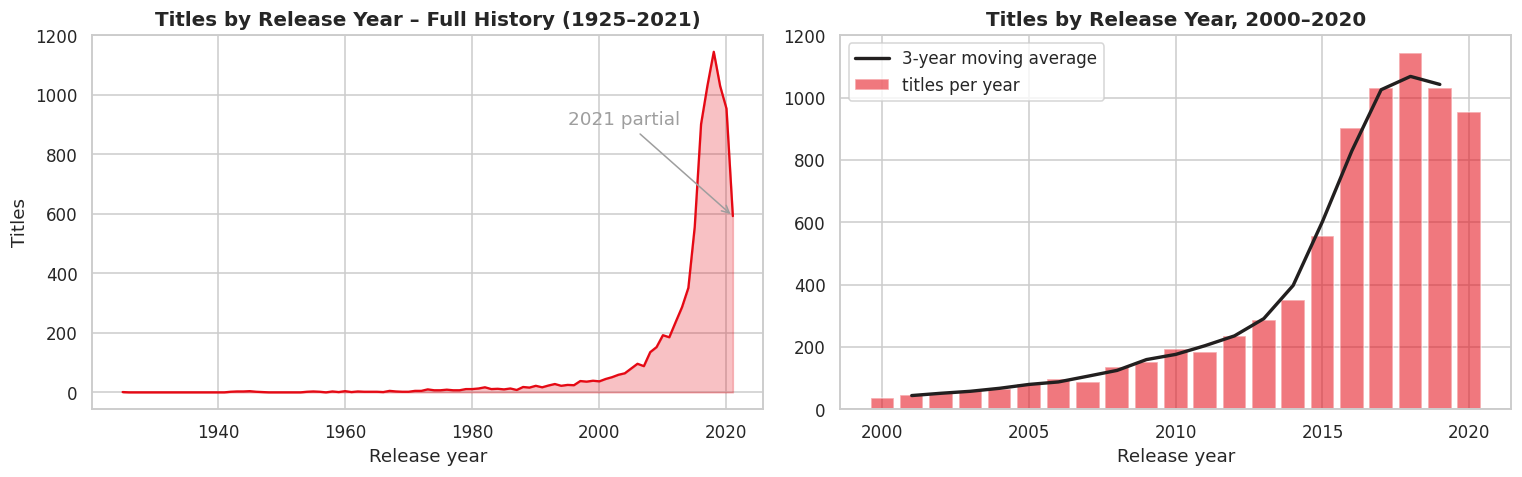

Peak release year: 2018 (1,144 titles).  2020: 953 (-17% vs peak)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].fill_between(yearly.index, yearly.values, color=RED, alpha=0.25); axes[0].plot(yearly.index, yearly.values, color=RED)
axes[0].set_title("Titles by Release Year – Full History (1925–2021)"); axes[0].set_xlabel("Release year"); axes[0].set_ylabel("Titles")
axes[0].annotate("2021 partial", (2021, yearly.loc[2021]), xytext=(1995, 900), arrowprops=dict(arrowstyle="->", color=GREY), color=GREY)

sm_avg = ts_total.rolling(3, center=True).mean()
axes[1].bar(ts_total.index, ts_total.values, color=RED, alpha=0.55, label="titles per year")
axes[1].plot(sm_avg.index, sm_avg.values, color=DARK, lw=2.2, label="3-year moving average")
axes[1].set_title("Titles by Release Year, 2000–2020"); axes[1].set_xlabel("Release year"); axes[1].legend()
plt.tight_layout(); plt.show()

peak = ts_total.idxmax()
print(f"Peak release year: {peak} ({ts_total.max():,} titles).  2020: {ts_total.loc[2020]:,} ({ts_total.loc[2020]/ts_total.max()-1:+.0%} vs peak)")

### 2.2 Growth rates

,Total,Movies,TV Shows
CAGR % per year,,,
2000–2010,17.9,16.6,25.6
2010–2016,29.4,27.5,35.7
2016–2018,12.7,7.9,24.7
2018–2020,-8.7,-17.8,7.4


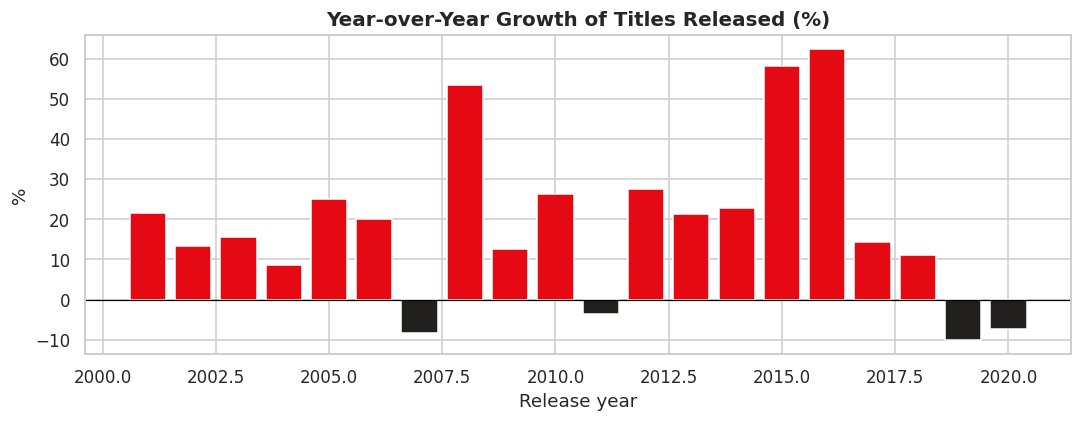

In [5]:
yoy = ts_total.pct_change() * 100

def cagr(s, a, b):
    return ((s.loc[b] / s.loc[a]) ** (1 / (b - a)) - 1) * 100

periods = [(2000, 2010), (2010, 2016), (2016, 2018), (2018, 2020)]
growth = pd.DataFrame({
    "period": [f"{a}–{b}" for a, b in periods],
    "Total":   [cagr(ts_total, a, b) for a, b in periods],
    "Movies":  [cagr(ts_movie, a, b) for a, b in periods],
    "TV Shows":[cagr(ts_tv, a, b)    for a, b in periods],
}).set_index("period")
display(growth.round(1).rename_axis("CAGR % per year"))

fig, ax = plt.subplots(figsize=(10, 4))
colors = [RED if v >= 0 else DARK for v in yoy.dropna().values]
ax.bar(yoy.dropna().index, yoy.dropna().values, color=colors)
ax.axhline(0, color="black", lw=0.8); ax.set_title("Year-over-Year Growth of Titles Released (%)"); ax.set_xlabel("Release year"); ax.set_ylabel("%")
plt.tight_layout(); plt.show()

### 2.3 Movies vs TV Shows

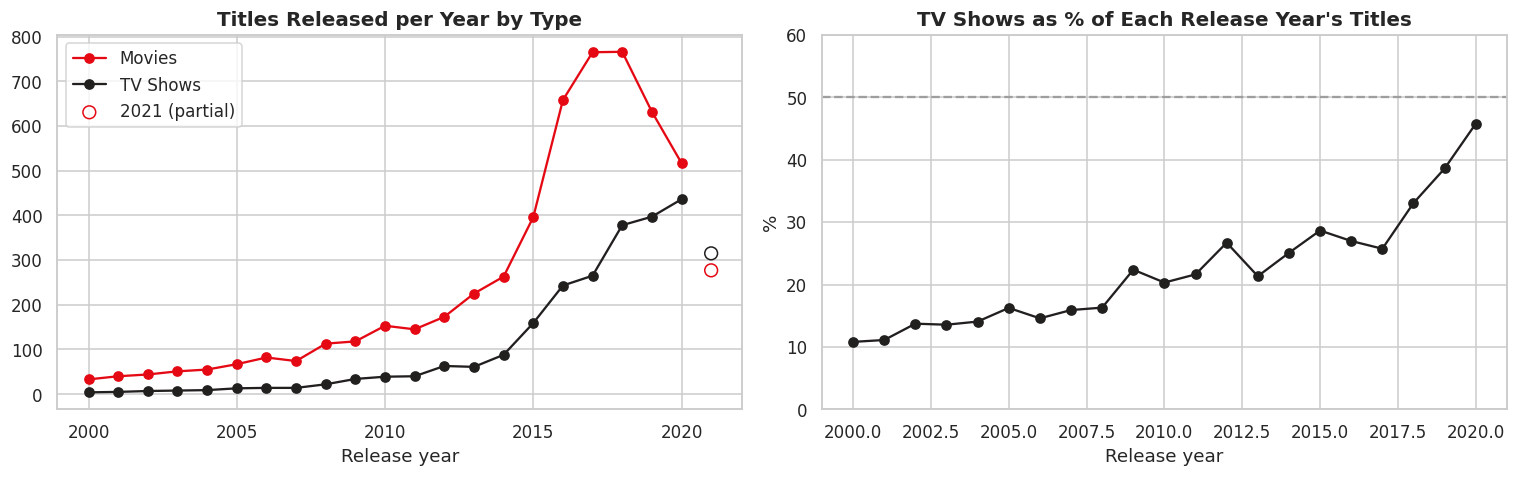

TV share of releases:  2010 = 20%,  2016 = 27%,  2020 = 46%
2021 year-to-date: 53% TV shows


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(ts_movie.index, ts_movie.values, color=RED, marker="o", label="Movies")
axes[0].plot(ts_tv.index, ts_tv.values, color=DARK, marker="o", label="TV Shows")
axes[0].scatter([2021, 2021], [ytd_2021["Movie"], ytd_2021["TV Show"]], facecolors="none", edgecolors=[RED, DARK], s=70, label="2021 (partial)")
axes[0].set_title("Titles Released per Year by Type"); axes[0].set_xlabel("Release year"); axes[0].legend()

tv_share = ts_tv / ts_total * 100
axes[1].plot(tv_share.index, tv_share.values, color=DARK, marker="o")
axes[1].axhline(50, color=GREY, ls="--"); axes[1].set_ylim(0, 60)
axes[1].set_title("TV Shows as % of Each Release Year's Titles"); axes[1].set_xlabel("Release year"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()
print(f"TV share of releases:  2010 = {tv_share.loc[2010]:.0f}%,  2016 = {tv_share.loc[2016]:.0f}%,  2020 = {tv_share.loc[2020]:.0f}%")
print(f"2021 year-to-date: {ytd_2021['TV Show'] / ytd_2021['total']:.0%} TV shows")

### 2.4 Release year vs year added to Netflix

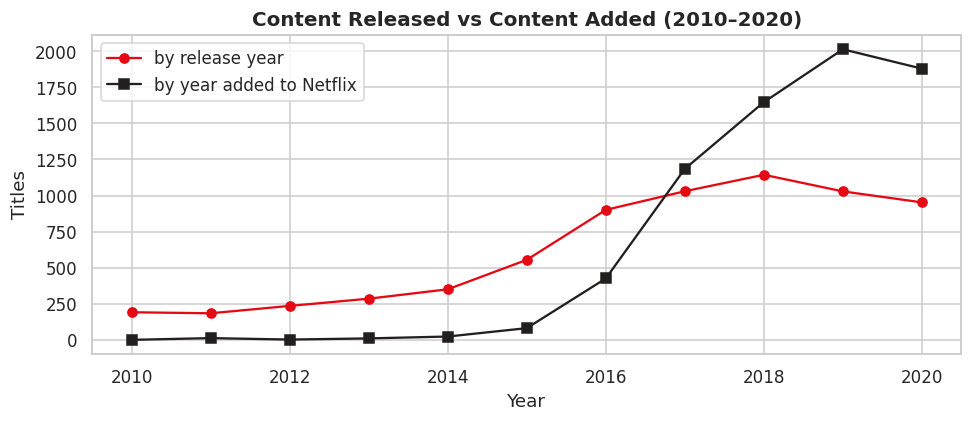

Release-year peak: 2018 | additions peak: 2019


In [7]:
added = df.groupby(df["date_added"].dt.year).size().loc[2010:2020]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ts_total.loc[2010:].index, ts_total.loc[2010:].values, marker="o", color=RED, label="by release year")
ax.plot(added.index, added.values, marker="s", color=DARK, label="by year added to Netflix")
ax.set_title("Content Released vs Content Added (2010–2020)"); ax.set_xlabel("Year"); ax.set_ylabel("Titles"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Release-year peak: {ts_total.idxmax()} | additions peak: {added.idxmax()}")

### 2.5 Stationarity check

In [8]:
def adf(series, name):
    stat, p, *_ = adfuller(series, regression="c", autolag="AIC")
    return {"series": name, "ADF statistic": round(stat, 2), "p-value": round(p, 3), "stationary at 5%?": "yes" if p < 0.05 else "no"}

pd.DataFrame([
    adf(ts_total, "titles (level)"),
    adf(ts_total.diff().dropna(), "titles (1st difference)"),
    adf(np.log(ts_total), "log(titles)"),
    adf(np.log(ts_total).diff().dropna(), "log(titles) 1st difference"),
])

,series,ADF statistic,p-value,stationary at 5%?
0,titles (level),0.75,0.991,no
1,titles (1st difference),5.59,1.000,no
2,log(titles),2.91,1.000,no
3,log(titles) 1st difference,-0.75,0.833,no


The level series is clearly non-stationary (p ≈ 0.99), so models must handle the trend explicitly (a regression trend, differencing in ARIMA, or a trend component in exponential smoothing). The first difference and log-difference are also not stationary at 5%, because growth first accelerates and then reverses. With only 21 observations the ADF test has very low power, so I treat it as a warning sign rather than proof and rely on **out-of-sample backtesting** to choose models instead of the test.

## Step 3 – Build forecasting models


In [ ]:
def as_ts(y):
    """Series with a proper annual DatetimeIndex (needed by statsmodels for forecasting)."""
    s = pd.Series(np.asarray(y, float), index=pd.date_range(str(y.index[0]), periods=len(y), freq="YS"))
    return s

# ---- point forecasts 
def fc_naive(y, h):     return np.repeat(y.iloc[-1], h)
def fc_poly(deg):
    def f(y, h):
        x = np.arange(len(y)); b = np.polyfit(x, y.values, deg)
        return np.polyval(b, np.arange(len(y), len(y) + h))
    return f
def fc_exp(y, h):
    x = np.arange(len(y)); b = np.polyfit(x, np.log(y.values), 1)
    return np.exp(np.polyval(b, np.arange(len(y), len(y) + h)))
def fc_ets(damped):
    def f(y, h):
        return np.asarray(ETSModel(as_ts(y), error="add", trend="add", damped_trend=damped).fit(disp=False).forecast(h))
    return f
def quiet(fn):
    # run fn() with statsmodels' start-parameter warnings silenced
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); return fn()

def fc_arima(y, h):
    return quiet(lambda: np.asarray(ARIMA(as_ts(y), order=(1, 1, 0), trend="t").fit().forecast(h)))
def fc_ens(y, h):          # simple average of two adaptive models (forecast combination)
    return (fc_ets(True)(y, h) + fc_arima(y, h)) / 2

MODELS = {
    "Naive": fc_naive, "Linear trend": fc_poly(1), "Quadratic trend": fc_poly(2), "Exponential trend": fc_exp,
    "Holt (additive trend)": fc_ets(False), "Damped Holt": fc_ets(True), "ARIMA(1,1,0)+drift": fc_arima,
    "Ensemble (Damped Holt + ARIMA)": fc_ens,
}

def metrics(actual, pred, naive_pred=None):
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    err = a - p
    out = {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()), "MAPE %": (np.abs(err) / a).mean() * 100}
    if naive_pred is not None:
        out["MASE"] = np.abs(err).mean() / np.abs(a - np.asarray(naive_pred, float)).mean()
    return out

In [10]:
def rolling_origin(series, first_test=2010):
    """1-step-ahead forecasts, refitting on all earlier years each time."""
    rows = {name: [] for name in MODELS}; actual = []
    for t in range(first_test, series.index.max() + 1):
        train = series.loc[:t - 1]; actual.append(series.loc[t])
        for name, f in MODELS.items():
            rows[name].append(f(train, 1)[0])
    preds = pd.DataFrame(rows, index=range(first_test, series.index.max() + 1)); preds.insert(0, "Actual", actual)
    return preds

def score_table(preds):
    naive = preds["Naive"]
    res = {n: metrics(preds["Actual"], preds[n], naive) for n in MODELS}
    return pd.DataFrame(res).T.sort_values("RMSE")

roll_total = rolling_origin(ts_total)
score_roll_total = score_table(roll_total)
score_roll_total.round(2)

,MAE,RMSE,MAPE %,MASE
"ARIMA(1,1,0)+drift",90.62,120.05,15.10,0.83
Ensemble (Damped Holt + ARIMA),91.95,121.47,15.73,0.85
Damped Holt,95.72,124.44,16.58,0.88
Holt (additive trend),100.18,133.43,15.81,0.92
Naive,108.82,141.72,18.09,1.00
Quadratic trend,145.94,197.95,19.60,1.34
Exponential trend,160.22,222.96,20.12,1.47
Linear trend,204.50,280.37,28.66,1.88


In [11]:
# Fixed-origin: train 2000-2016, forecast 2017-2020 (4 years ahead)
split = 2016
train, test = ts_total.loc[:split], ts_total.loc[split + 1:]
fixed = pd.DataFrame({n: f(train, len(test)) for n, f in MODELS.items()}, index=test.index)
fixed.insert(0, "Actual", test.values)
score_fixed = pd.DataFrame({n: metrics(test, fixed[n]) for n in MODELS}).T.sort_values("RMSE")
display(fixed.round(0).astype(int))
score_fixed.round(2)

,Actual,Naive,Linear trend,Quadratic trend,Exponential trend,Holt (additive trend),Damped Holt,"ARIMA(1,1,0)+drift",Ensemble (Damped Holt + ARIMA)
release_year,,,,,,,,,
2017,1030,901,530,801,670,1247,1240,1229,1234
2018,1144,901,566,927,800,1593,1572,1540,1556
2019,1029,901,602,1063,954,1939,1898,1835,1866
2020,953,901,638,1208,1139,2285,2217,2116,2167


,MAE,RMSE,MAPE %
Naive,138.00,153.93,12.92
Quadratic trend,183.64,203.48,17.81
Exponential trend,241.42,268.67,22.97
Linear trend,454.66,464.86,43.37
"ARIMA(1,1,0)+drift",640.84,741.39,63.56
Ensemble (Damped Holt + ARIMA),666.85,772.30,66.15
Damped Holt,692.86,803.22,68.73
Holt (additive trend),726.95,844.20,72.13


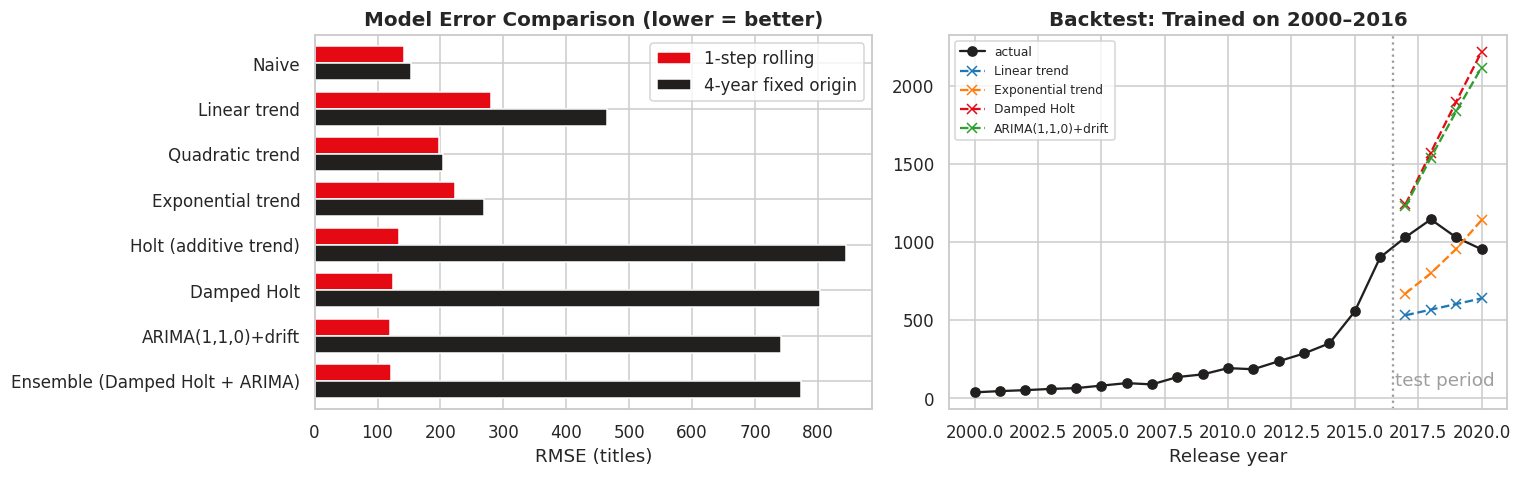

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# model comparison (RMSE)
cmp = pd.DataFrame({"1-step rolling": score_roll_total["RMSE"], "4-year fixed origin": score_fixed["RMSE"]}).loc[list(MODELS)]
cmp.plot(kind="barh", ax=axes[0], color=[RED, DARK], width=0.75)
axes[0].invert_yaxis(); axes[0].set_xlabel("RMSE (titles)"); axes[0].set_title("Model Error Comparison (lower = better)"); axes[0].legend(title="")

# fixed-origin backtest chart
axes[1].plot(ts_total.index, ts_total.values, color=DARK, marker="o", label="actual")
for n, c in zip(["Linear trend", "Exponential trend", "Damped Holt", "ARIMA(1,1,0)+drift"], [BLUE, "#ff7f0e", RED, "#2ca02c"]):
    axes[1].plot(fixed.index, fixed[n], ls="--", marker="x", color=c, label=n)
axes[1].axvline(split + 0.5, color=GREY, ls=":"); axes[1].text(split + 0.6, 80, "test period", color=GREY)
axes[1].set_title("Backtest: Trained on 2000–2016"); axes[1].set_xlabel("Release year"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [13]:
# Same evaluation for Movies and TV Shows separately
roll_movie, roll_tv = rolling_origin(ts_movie), rolling_origin(ts_tv)
score_movie, score_tv = score_table(roll_movie), score_table(roll_tv)

print("1-step rolling RMSE by model and series:")
rmse_all = pd.DataFrame({"Total": score_roll_total["RMSE"], "Movies": score_movie["RMSE"], "TV Shows": score_tv["RMSE"]}).loc[list(MODELS)]
display(rmse_all.round(1))
best = {"Total": rmse_all["Total"].idxmin(), "Movies": rmse_all["Movies"].idxmin(), "TV Shows": rmse_all["TV Shows"].idxmin()}
print("Best model by 1-step rolling RMSE:", best)

1-step rolling RMSE by model and series:


,Total,Movies,TV Shows
Naive,141.7,110.9,50.9
Linear trend,280.4,191.2,112.3
Quadratic trend,198.0,172.5,49.0
Exponential trend,223.0,181.6,52.0
Holt (additive trend),133.4,112.9,40.0
Damped Holt,124.4,100.0,43.8
"ARIMA(1,1,0)+drift",120.0,98.2,45.7
Ensemble (Damped Holt + ARIMA),121.5,98.3,44.0


Best model by 1-step rolling RMSE: {'Total': 'ARIMA(1,1,0)+drift', 'Movies': 'ARIMA(1,1,0)+drift', 'TV Shows': 'Holt (additive trend)'}


### 3.1 Final models and forecast intervals (2021–2025)

In [14]:
H = 5
future_years = list(range(last_full_year + 1, last_full_year + 1 + H))
Z = 1.2816     # 80% interval

def forecast_ci(name, y, h=H):
    """Point forecast and 80% prediction interval for each model family."""
    x = np.arange(len(y)); xf = np.arange(len(y), len(y) + h)
    if name in ("Linear trend", "Quadratic trend", "Exponential trend"):
        deg = 2 if name.startswith("Quad") else 1
        target = np.log(y.values) if name.startswith("Exp") else y.values
        X = np.vander(x, deg + 1); Xf = np.vander(xf, deg + 1)
        pr = sm.OLS(target, X).fit().get_prediction(Xf).summary_frame(alpha=0.2)
        mean, lo, hi = pr["mean"].values, pr["obs_ci_lower"].values, pr["obs_ci_upper"].values
        if name.startswith("Exp"): mean, lo, hi = np.exp(mean), np.exp(lo), np.exp(hi)
    elif name in ("Holt (additive trend)", "Damped Holt"):
        r = ETSModel(as_ts(y), error="add", trend="add", damped_trend=name.startswith("Damped")).fit(disp=False)
        pr = r.get_prediction(start=len(y), end=len(y) + h - 1).summary_frame(alpha=0.2)
        mean, lo, hi = pr["mean"].values, pr["pi_lower"].values, pr["pi_upper"].values
    elif name.startswith("Ensemble"):      # average of the two component forecasts and of their interval limits
        a, b = forecast_ci("Damped Holt", y, h), forecast_ci("ARIMA(1,1,0)+drift", y, h)
        mean, lo, hi = ((a["forecast"] + b["forecast"]) / 2).values, ((a["lower"] + b["lower"]) / 2).values, ((a["upper"] + b["upper"]) / 2).values
    elif name.startswith("ARIMA"):
        r = quiet(lambda: ARIMA(as_ts(y), order=(1, 1, 0), trend="t").fit().get_forecast(h))
        ci = r.conf_int(alpha=0.2); mean, lo, hi = r.predicted_mean.values, ci.iloc[:, 0].values, ci.iloc[:, 1].values
    else:   # naive / random walk
        sigma = np.diff(y.values).std(ddof=1); mean = np.repeat(y.iloc[-1], h)
        lo, hi = mean - Z * sigma * np.sqrt(np.arange(1, h + 1)), mean + Z * sigma * np.sqrt(np.arange(1, h + 1))
    return pd.DataFrame({"forecast": mean, "lower": np.maximum(lo, 0), "upper": hi}, index=future_years)

series = {"Total": ts_total, "Movies": ts_movie, "TV Shows": ts_tv}
final = {k: forecast_ci(best[k], s) for k, s in series.items()}

# every model's point forecast for the total series (used to show the spread between models)
all_models_total = pd.DataFrame({n: f(ts_total, H) for n, f in MODELS.items()}, index=future_years)

for k, v in final.items():
    print(f"\n{k}  –  {best[k]}")
    display(v.round(0).astype(int))


Total  –  ARIMA(1,1,0)+drift


,forecast,lower,upper
2021,926,825,1027
2022,927,740,1114
2023,943,676,1210
2024,968,630,1307
2025,999,596,1401



Movies  –  ARIMA(1,1,0)+drift


,forecast,lower,upper
2021,448,368,527
2022,408,255,560
2023,386,163,610
2024,377,87,667
2025,375,25,726



TV Shows  –  Holt (additive trend)


,forecast,lower,upper
2021,479,446,512
2022,511,458,564
2023,543,461,625
2024,575,458,692
2025,607,450,764


### 3.2 Error diagnostics of the selected total-series model

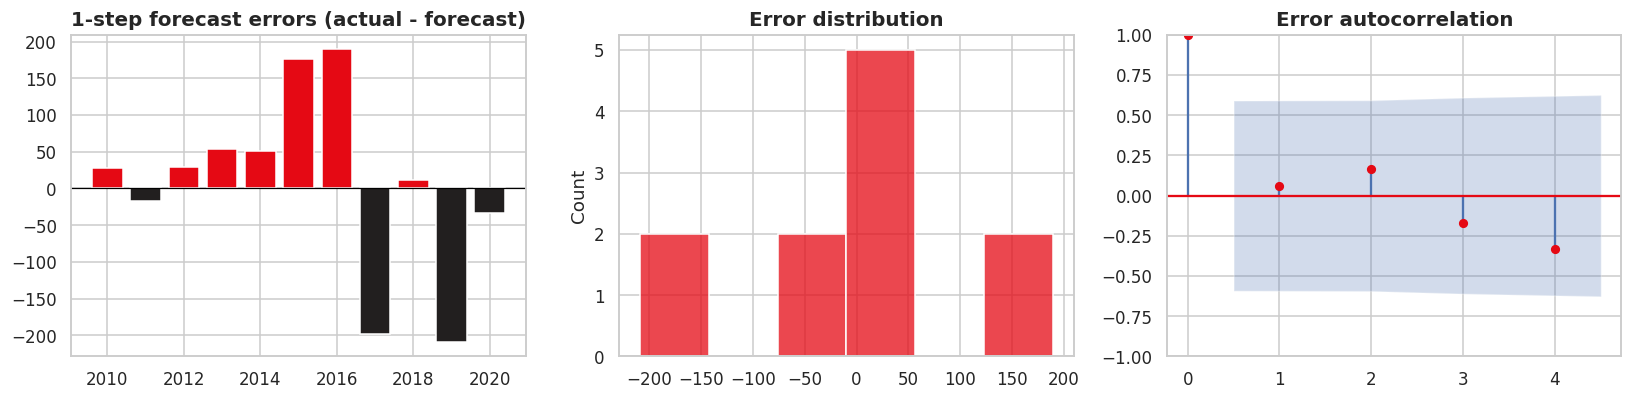

Model: ARIMA(1,1,0)+drift | mean error = 7.3 titles, std = 125.7, MAPE = 15.1%


In [15]:
# Model-agnostic diagnostics: 1-step-ahead forecast errors of the selected model over 2010-2020
name = best["Total"]
res = (roll_total["Actual"] - roll_total[name])

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(res.index, res.values, color=[RED if v >= 0 else DARK for v in res.values]); axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title("1-step forecast errors (actual - forecast)")
sns.histplot(res, bins=6, kde=False, color=RED, ax=axes[1]); axes[1].set_title("Error distribution")
plot_acf(res, lags=4, ax=axes[2], color=RED); axes[2].set_title("Error autocorrelation")
plt.tight_layout(); plt.show()
print(f"Model: {name} | mean error = {res.mean():.1f} titles, std = {res.std():.1f}, MAPE = {(res.abs() / roll_total['Actual']).mean():.1%}")

## Step 4 – Visualize future predictions

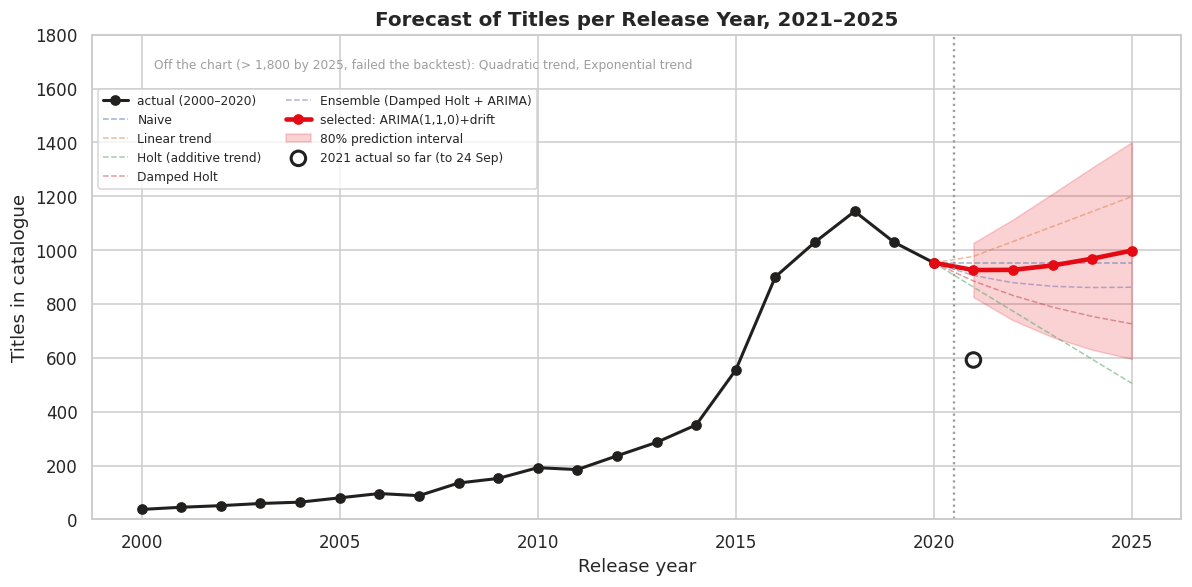

In [16]:
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(ts_total.index, ts_total.values, color=DARK, marker="o", lw=2, label="actual (2000–2020)")

# other candidate models as thin lines -> shows model uncertainty
CAP = 1800
too_high = [n for n in all_models_total.columns if all_models_total[n].max() > CAP]
for n in all_models_total.columns:
    if n != best["Total"] and n not in too_high:
        ax.plot([last_full_year] + future_years, [ts_total.iloc[-1]] + all_models_total[n].tolist(), lw=1, alpha=0.55, ls="--", label=n)
if too_high:
    ax.text(2000.3, CAP * 0.93, "Off the chart (> %s by 2025, failed the backtest): %s" % (f"{CAP:,}", ", ".join(too_high)), fontsize=8, color=GREY)

f = final["Total"]
ax.plot([last_full_year] + future_years, [ts_total.iloc[-1]] + f["forecast"].tolist(), color=RED, lw=3, marker="o", label=f"selected: {best['Total']}")
ax.fill_between(future_years, f["lower"], f["upper"], color=RED, alpha=0.18, label="80% prediction interval")
ax.scatter([2021], [ytd_2021["total"]], s=90, facecolors="none", edgecolors=DARK, linewidths=2, zorder=5, label="2021 actual so far (to 24 Sep)")
ax.axvline(last_full_year + 0.5, color=GREY, ls=":")
ax.set_title("Forecast of Titles per Release Year, 2021–2025"); ax.set_xlabel("Release year"); ax.set_ylabel("Titles in catalogue")
ax.set_ylim(0, CAP); ax.legend(fontsize=8, ncol=2, loc="upper left", bbox_to_anchor=(0.0, 0.9))
plt.tight_layout(); plt.show()

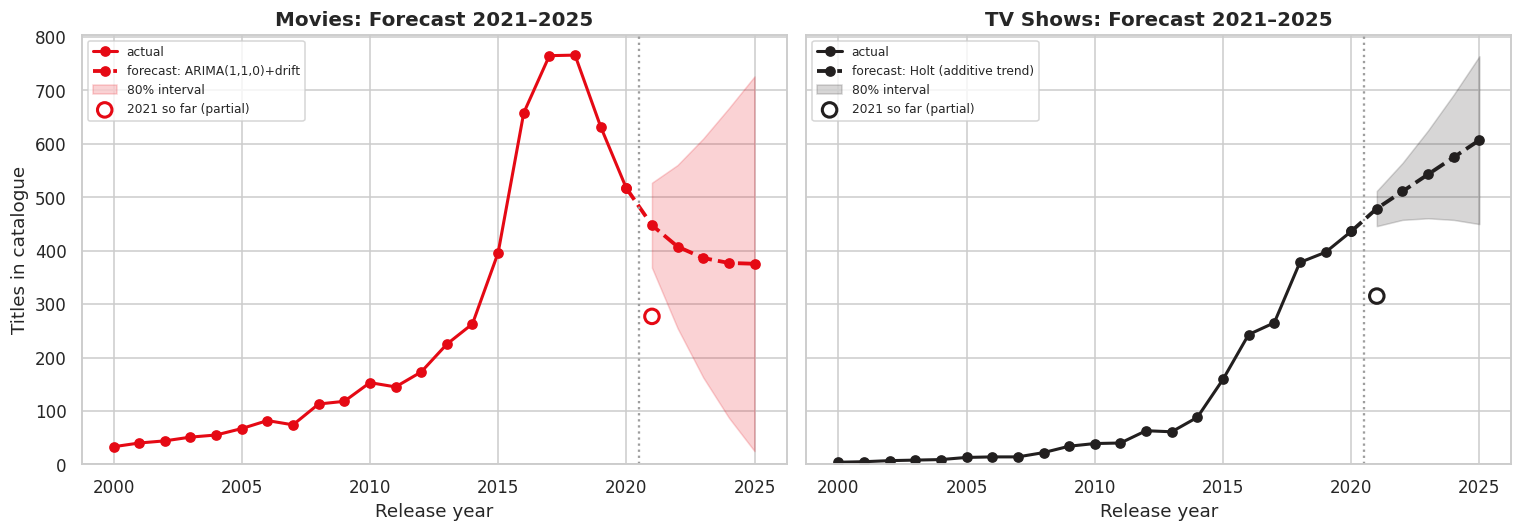

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, key, color in zip(axes, ["Movies", "TV Shows"], [RED, DARK]):
    s, f = series[key], final[key]
    ax.plot(s.index, s.values, color=color, marker="o", lw=2, label="actual")
    ax.plot([last_full_year] + future_years, [s.iloc[-1]] + f["forecast"].tolist(), color=color, ls="--", marker="o", lw=2.5, label=f"forecast: {best[key]}")
    ax.fill_between(future_years, f["lower"], f["upper"], color=color, alpha=0.18, label="80% interval")
    ytd = ytd_2021["Movie" if key == "Movies" else "TV Show"]
    ax.scatter([2021], [ytd], s=90, facecolors="none", edgecolors=color, linewidths=2, zorder=5, label="2021 so far (partial)")
    ax.axvline(last_full_year + 0.5, color=GREY, ls=":"); ax.set_title(f"{key}: Forecast 2021–2025"); ax.set_xlabel("Release year"); ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("Titles in catalogue"); plt.ylim(bottom=0); plt.tight_layout(); plt.show()

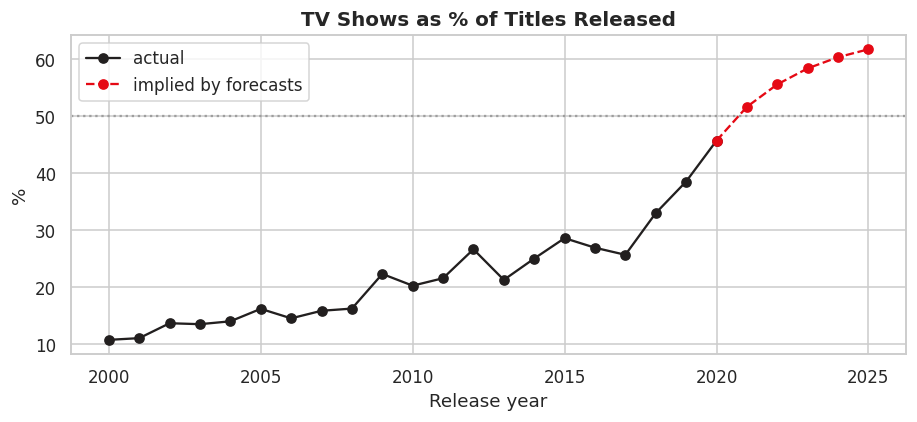

,TV share % (forecast)
2021,51.7
2022,55.6
2023,58.4
2024,60.4
2025,61.8


In [18]:
# Forecast of the TV share of releases
tv_share_fc = final["TV Shows"]["forecast"] / (final["TV Shows"]["forecast"] + final["Movies"]["forecast"]) * 100
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(tv_share.index, tv_share.values, color=DARK, marker="o", label="actual")
ax.plot([last_full_year] + future_years, [tv_share.iloc[-1]] + tv_share_fc.tolist(), color=RED, ls="--", marker="o", label="implied by forecasts")
ax.axhline(50, color=GREY, ls=":"); ax.set_title("TV Shows as % of Titles Released"); ax.set_xlabel("Release year"); ax.set_ylabel("%"); ax.legend()
plt.tight_layout(); plt.show()
tv_share_fc.round(1).to_frame("TV share % (forecast)")

## Step 5 – Interpret results

In [19]:
table = pd.DataFrame({
    "Total":    final["Total"]["forecast"],
    "Movies":   final["Movies"]["forecast"],
    "TV Shows": final["TV Shows"]["forecast"],
}).round(0).astype(int)
table.index.name = "release year"
table.loc["2020 actual"] = [ts_total.loc[2020], ts_movie.loc[2020], ts_tv.loc[2020]]
display(table.iloc[[-1] + list(range(len(table) - 1))])

chg = (final["Total"]["forecast"].iloc[-1] / ts_total.loc[2020] - 1) * 100
print(f"Selected total model: {best['Total']}  →  2025 forecast is {chg:+.0f}% vs 2020.")
print(f"2021 so far (to 24 Sep): {ytd_2021['total']} total vs forecast for full 2021: {final['Total']['forecast'].loc[2021]:.0f}")

,Total,Movies,TV Shows
release year,,,
2020 actual,953,517,436
2021,926,448,479
2022,927,408,511
2023,943,386,543
2024,968,377,575
2025,999,375,607


Selected total model: ARIMA(1,1,0)+drift  →  2025 forecast is +5% vs 2020.
2021 so far (to 24 Sep): 592 total vs forecast for full 2021: 926


## Thank You